In [48]:
import pandas as pd

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')
import matplotlib.pyplot as plt
import seaborn as sns

# Display the first few rows
#print(df.tail())

In [18]:
data

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.70,1.00,0.5,0.00,0.00,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.00,3.50,0.5,3.75,0.00,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.30,3.50,0.5,3.00,0.00,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.00,3.50,0.5,2.00,0.00,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.90,3.50,0.5,3.20,0.00,1.0,16.10,2.5,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2964619,2,2024-01-31 23:45:59,2024-01-31 23:54:36,NaN,3.18,NaN,None,107,263,0,15.77,0.00,0.5,2.00,0.00,1.0,21.77,NaN,NaN
2964620,1,2024-01-31 23:13:07,2024-01-31 23:27:52,NaN,4.00,NaN,None,114,236,0,18.40,1.00,0.5,2.34,0.00,1.0,25.74,NaN,NaN
2964621,2,2024-01-31 23:19:00,2024-01-31 23:38:00,NaN,3.33,NaN,None,211,25,0,19.97,0.00,0.5,0.00,0.00,1.0,23.97,NaN,NaN
2964622,2,2024-01-31 23:07:23,2024-01-31 23:25:14,NaN,3.06,NaN,None,107,13,0,23.88,0.00,0.5,5.58,0.00,1.0,33.46,NaN,NaN


In [19]:
data.shape
print('Records in Dataset',data.shape[0])
print('Factors in Dataset',data.shape[1])

Records in Dataset 2964624
Factors in Dataset 19


In [20]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee'],
      dtype='object')

In [49]:
# Convert datetime columns to datetime objects
data['tpep_pickup_datetime'] = pd.to_datetime(data['tpep_pickup_datetime'])
data['tpep_dropoff_datetime'] = pd.to_datetime(data['tpep_dropoff_datetime'])

In [50]:
# Calculate trip duration in minutes
data['trip_duration'] = (data['tpep_dropoff_datetime'] - data['tpep_pickup_datetime']).dt.total_seconds() / 60


In [51]:
# Filter out trips with 0 or negative duration or distance
data = data[(data['trip_duration'] > 0) & (data['trip_distance'] > 0)]

In [52]:
# Add new columns for pickup day and hour
data['pickup_day'] = data['tpep_pickup_datetime'].dt.day_name()
data['pickup_hour'] = data['tpep_pickup_datetime'].dt.hour

In [53]:
data.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee', 'trip_duration',
       'pickup_day', 'pickup_hour'],
      dtype='object')

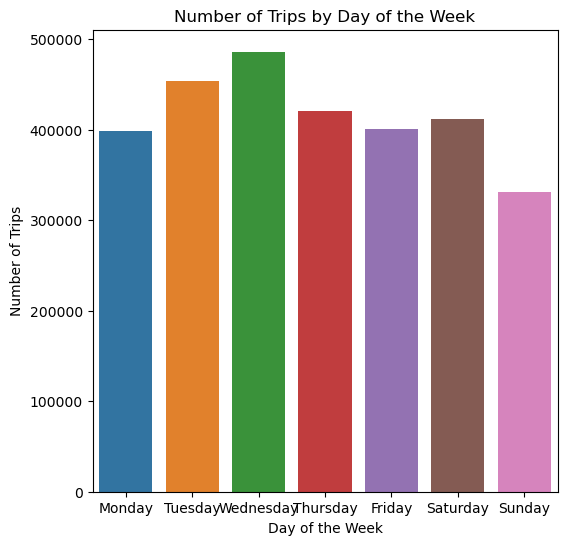

In [30]:
# 1. Trips by day of the week
plt.figure(figsize=(6, 6))
sns.countplot(data=data, x='pickup_day', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.title('Number of Trips by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Trips')
plt.show()

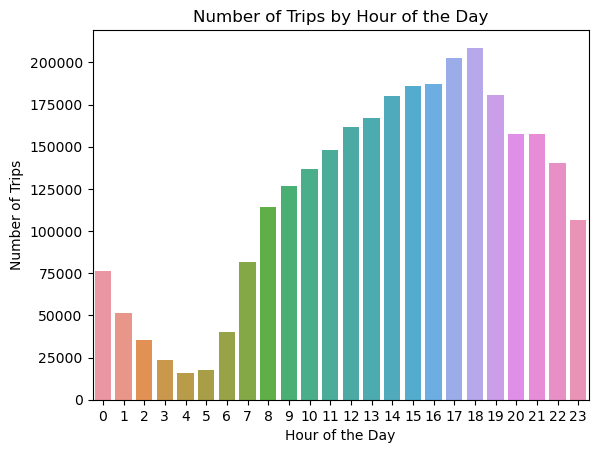

In [33]:
# Replace 'hour_of_day' with 'pickup_hour'
sns.countplot(data=data, x='pickup_hour')
plt.title('Number of Trips by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Trips')
plt.show()


In [16]:
print(data.columns)


Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee'],
      dtype='object')


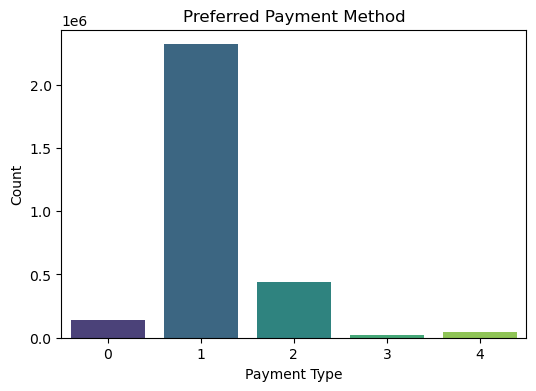

In [34]:
# Preferred payment method analysis
payment_methods = df['payment_type'].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=payment_methods.index, y=payment_methods.values, palette="viridis")
plt.title('Preferred Payment Method')
plt.xlabel('Payment Type')
plt.ylabel('Count')
plt.show()

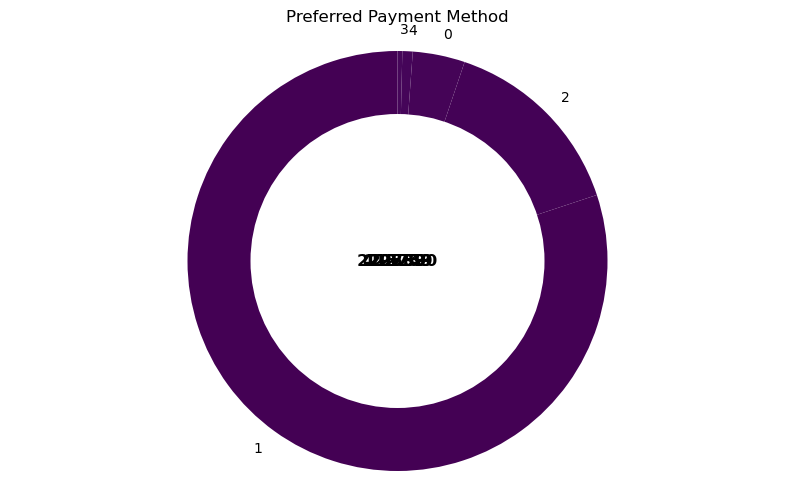

In [42]:
import matplotlib.pyplot as plt

# Calculate value counts for payment methods
payment_methods = df['payment_type'].value_counts()

# Create a donut chart
plt.figure(figsize=(10, 6))
plt.pie(payment_methods, labels=payment_methods.index, autopct='', startangle=90, pctdistance=0.85, colors=plt.cm.viridis(range(len(payment_methods))))

# Draw a circle at the center of the pie to create a donut chart effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')  # Adjust the radius for the donut hole
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

# Add counts inside the donut chart
for i, value in enumerate(payment_methods):
    plt.text(0, 0, f'{value}', ha='center', va='center', fontsize=12, color='black', weight='bold')

# Set title
plt.title('Preferred Payment Method')

# Show plot
plt.axis('equal')  # Equal aspect ratio ensures that the donut is circular.
plt.show()


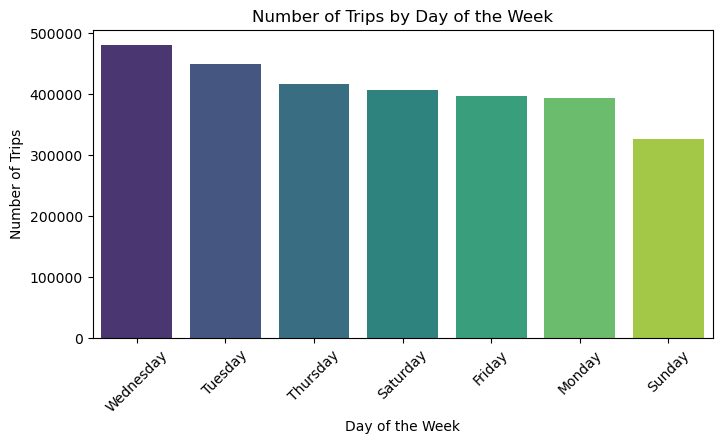

C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


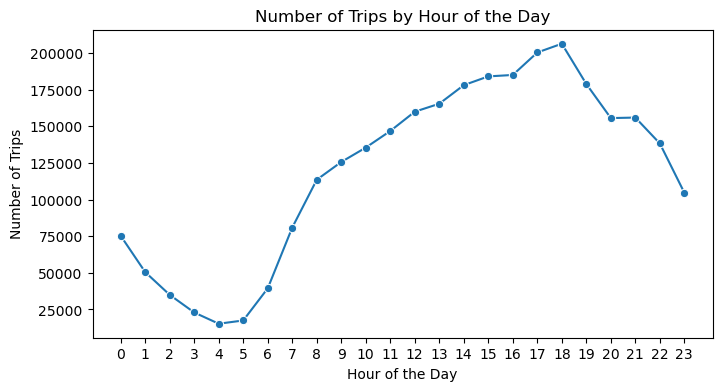

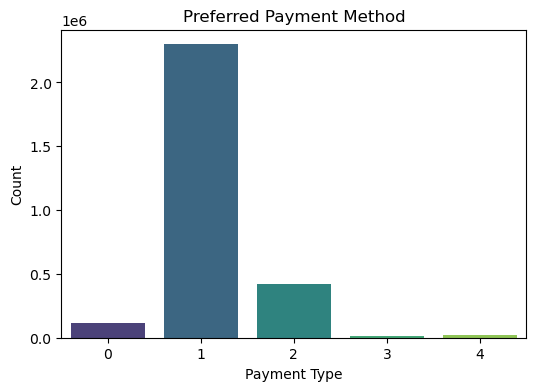

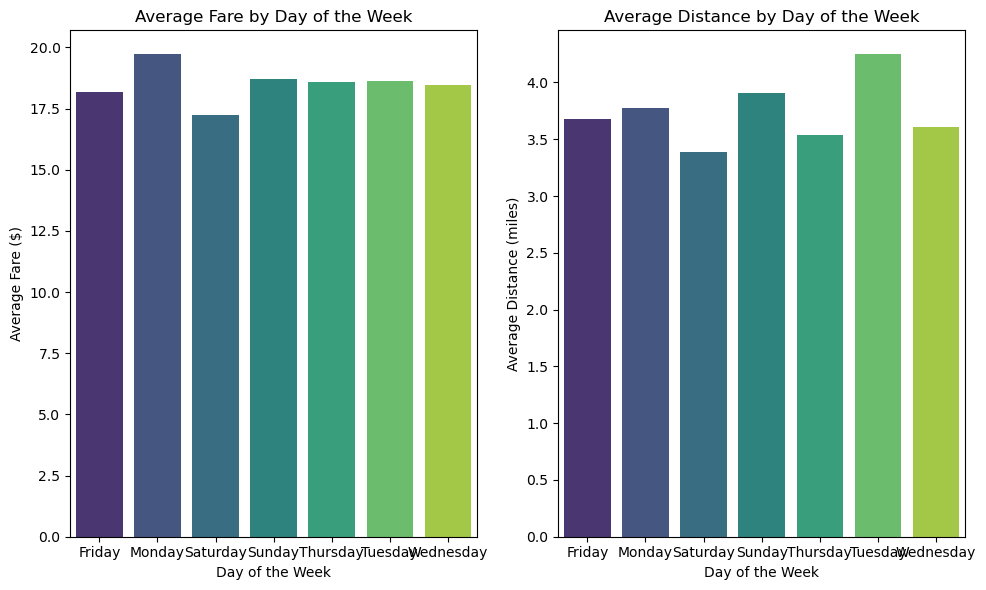

Peak trip hour: 18
Busiest day: Wednesday
Average fare amount: $ 18.5
Average distance covered by cabs: 3.73 miles


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_parquet("yellow_tripdata_2024-01.parquet")

# Convert datetime columns to datetime format
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

# Add new columns for analysis
df['day_of_week'] = df['tpep_pickup_datetime'].dt.day_name()  # Day of the week
df['hour_of_day'] = df['tpep_pickup_datetime'].dt.hour  # Hour of the day
df['trip_duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60  # Trip duration in minutes

# Data cleaning
df = df[(df['trip_distance'] > 0) & (df['fare_amount'] > 0)]  # Remove zero or negative values

# Analysis of trip frequency by day of the week
trips_by_day = df['day_of_week'].value_counts()
plt.figure(figsize=(8, 4))
sns.barplot(x=trips_by_day.index, y=trips_by_day.values, palette="viridis")
plt.title('Number of Trips by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()

# Analysis of trip frequency by hour of the day
trips_by_hour = df['hour_of_day'].value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.lineplot(x=trips_by_hour.index, y=trips_by_hour.values, marker="o")
plt.title('Number of Trips by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Trips')
plt.xticks(range(24))  # Show all hours from 0 to 23
plt.show()

# Preferred payment method analysis
payment_methods = df['payment_type'].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=payment_methods.index, y=payment_methods.values, palette="viridis")
plt.title('Preferred Payment Method')
plt.xlabel('Payment Type')
plt.ylabel('Count')
plt.show()

# Average fare and distance by day of the week
avg_fare_by_day = df.groupby('day_of_week')['fare_amount'].mean()
avg_distance_by_day = df.groupby('day_of_week')['trip_distance'].mean()

plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
sns.barplot(x=avg_fare_by_day.index, y=avg_fare_by_day.values, palette="viridis")
plt.title('Average Fare by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Fare ($)')

plt.subplot(1, 2, 2)
sns.barplot(x=avg_distance_by_day.index, y=avg_distance_by_day.values, palette="viridis")
plt.title('Average Distance by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Distance (miles)')

plt.tight_layout()
plt.show()

# Insights
peak_hours = trips_by_hour.idxmax()
busiest_day = trips_by_day.idxmax()
average_fare = df['fare_amount'].mean()
average_distance = df['trip_distance'].mean()

print("Peak trip hour:", peak_hours)
print("Busiest day:", busiest_day)
print("Average fare amount: $", round(average_fare, 2))
print("Average distance covered by cabs:", round(average_distance, 2), "miles")


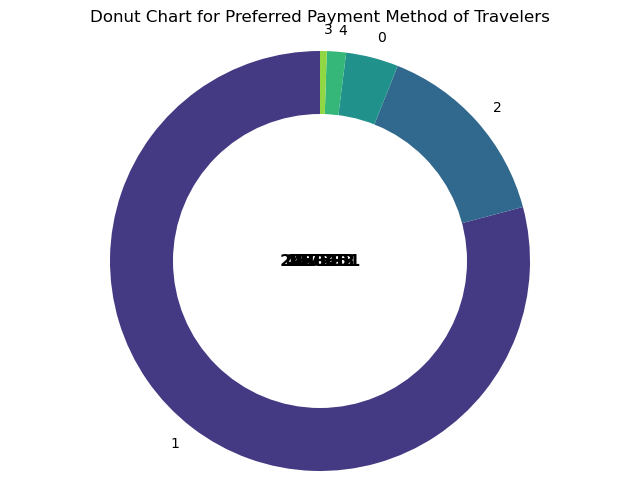

In [54]:


# Map payment types to labels
payment_mapping = {
    0: 'Others',
    1: 'Credit',
    2: 'Cash',
    3: 'Others',
    4: 'Others'
}

# Map the payment types in the DataFrame
df['payment_type'] = data['payment_type'].map(payment_mapping)

# Calculate value counts for payment methods
payment_methods = data['payment_type'].value_counts()

# Create a donut chart
plt.figure(figsize=(8, 6))
plt.pie(payment_methods, labels=payment_methods.index, autopct='', startangle=90, pctdistance=0.85, colors=sns.color_palette("viridis", len(payment_methods)))

# Draw a circle at the center of the pie to create a donut chart effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')  # Adjust the radius for the donut hole
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

# Add counts inside the donut chart
for i, value in enumerate(payment_methods):
    plt.text(0, 0, f'{value}', ha='center', va='center', fontsize=12, color='black', weight='bold')

# Set title
plt.title('Donut Chart for Preferred Payment Method of Travelers')

# Show plot
plt.axis('equal')  # Equal aspect ratio ensures that the donut is circular.
plt.show()


In [47]:
data.columns

AttributeError: 'dict' object has no attribute 'columns'

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Parquet file
df = pd.read_parquet('yellow_tripdata_2024-01.parquet')

# Display the first few rows
print("Data Preview:")
print(df.head())

# Overview of dataset structure
print("\nDataset Info:")
print(df.info())

# Basic statistics for numerical columns
print("\nStatistical Summary:")
print(df.describe())

# Check for missing values
print("\nMissing Values in Dataset:")
print(df.isnull().sum())

# Drop rows with missing values (optional, based on the analysis)
df_clean = df.dropna()

Data Preview:
   VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  \
0         2  2024-01-01 00:57:55   2024-01-01 01:17:43              1.0   
1         1  2024-01-01 00:03:00   2024-01-01 00:09:36              1.0   
2         1  2024-01-01 00:17:06   2024-01-01 00:35:01              1.0   
3         1  2024-01-01 00:36:38   2024-01-01 00:44:56              1.0   
4         1  2024-01-01 00:46:51   2024-01-01 00:52:57              1.0   

   trip_distance  RatecodeID store_and_fwd_flag  PULocationID  DOLocationID  \
0           1.72         1.0                  N           186            79   
1           1.80         1.0                  N           140           236   
2           4.70         1.0                  N           236            79   
3           1.40         1.0                  N            79           211   
4           0.80         1.0                  N           211           148   

   payment_type  fare_amount  extra  mta_tax  tip_amount  to

C:\Users\User\AppData\Local\Temp\ipykernel_4324\943603108.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['trip_duration'] = (pd.to_datetime(df_clean['tpep_dropoff_datetime']) - pd.to_datetime(df_clean['tpep_pickup_datetime'])).dt.total_seconds() / 60  # duration in minutes
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


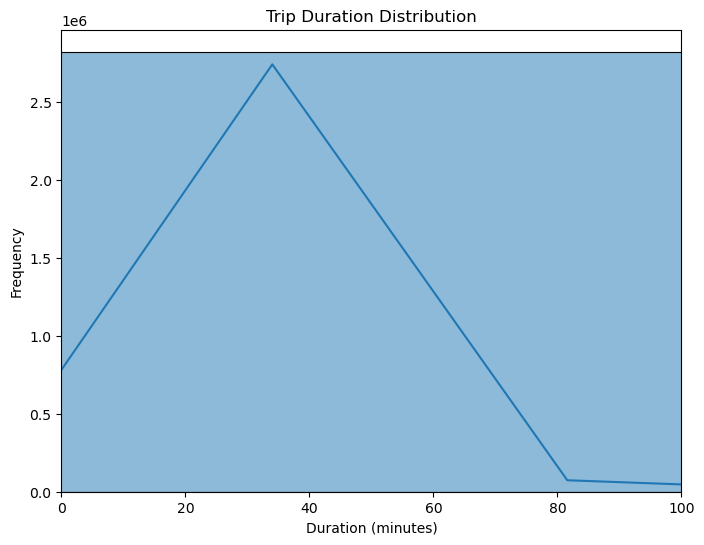

In [2]:
# 3. Distribution of Trip Duration
df_clean['trip_duration'] = (pd.to_datetime(df_clean['tpep_dropoff_datetime']) - pd.to_datetime(df_clean['tpep_pickup_datetime'])).dt.total_seconds() / 60  # duration in minutes

plt.figure(figsize=(8, 6))
sns.histplot(df_clean['trip_duration'], bins=50, kde=True)
plt.title("Trip Duration Distribution")
plt.xlabel("Duration (minutes)")
plt.ylabel("Frequency")
plt.xlim(0, 100)  # Optional: Limit for better visualization (ignore extreme outliers)
plt.show()

C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


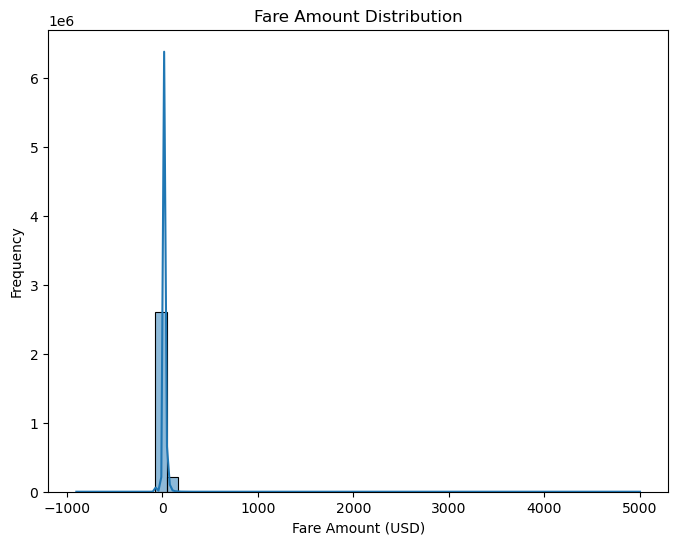

In [3]:
# 4. Fare Amount Distribution
plt.figure(figsize=(8, 6))
sns.histplot(df_clean['fare_amount'], bins=50, kde=True)
plt.title("Fare Amount Distribution")
plt.xlabel("Fare Amount (USD)")
plt.ylabel("Frequency")
plt.show()

In [5]:
# 5. Correlation Heatmap between numerical features
plt.figure(figsize=(10, 6))
corr = df_clean[['trip_distance', 'fare_amount', 'total_amount', 'trip_duration', 'passenger_count']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap of Key Features")
plt.show()

KeyError: "['trip_duration'] not in index"

<Figure size 1000x600 with 0 Axes>

In [ ]:
# 6. Pick-up and Drop-off Location Density (Heatmaps)
plt.figure(figsize=(10, 6))
sns.kdeplot(x=df_clean['PULocationID'], y=df_clean['DOLocationID'], cmap="Reds", fill=True)
plt.title("Pick-up and Drop-off Location Density")
plt.xlabel("Pick-up Location ID")
plt.ylabel("Drop-off Location ID")
plt.show()

C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


In [ ]:
# 7. Payment Type Distribution
plt.figure(figsize=(8, 6))
sns.countplot(x='payment_type', data=df_clean)
plt.title("Distribution of Payment Types")
plt.xlabel("Payment Type")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# 9. Congestion Surcharge Analysis
plt.figure(figsize=(8, 6))
sns.histplot(df_clean['congestion_surcharge'], bins=30, kde=True)
plt.title("Congestion Surcharge Distribution")
plt.xlabel("Congestion Surcharge (USD)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# 1. Distribution of Passenger Counts
plt.figure(figsize=(8, 6))
sns.countplot(x='passenger_count', data=df_clean)
plt.title("Distribution of Passenger Counts")
plt.xlabel("Passenger Count")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# 2. Distribution of Trip Distances
plt.figure(figsize=(8, 6))
sns.histplot(df_clean['trip_distance'], bins=50, kde=True)
plt.title("Trip Distance Distribution")
plt.xlabel("Distance (miles)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# 8. RatecodeID Distribution
plt.figure(figsize=(8, 6))
sns.countplot(x='RatecodeID', data=df_clean)
plt.title("Distribution of RatecodeID")
plt.xlabel("RatecodeID")
plt.ylabel("Frequency")
plt.show()